# Notebook 09 — PSI Monitoring

**Enterprise Credit Risk Modeling & Validation Framework**

Population Stability Index (PSI) monitoring assesses whether the trained PD model
and its input features remain stable from the training period through the validation
and out-of-time (OOT) deployment windows.

**Reference period:** Training set — 2007–2015 (887,411 loans)

**Monitoring windows:**
- Validation: 2016 (434,406 loans)
- OOT: 2017–2018 (938,821 loans)

**PSI thresholds:**

| PSI | Status | Action |
|-----|--------|--------|
| < 0.10 | 🟢 Stable | No action required |
| 0.10–0.25 | 🟡 Monitor | Investigate, consider recalibration |
| > 0.25 | 🔴 Unstable | Model redevelopment likely needed |

**Outputs:**
- `artifacts/psi_scores.csv` — model score PSI (all 4 models, Train→Val and Train→OOT)
- `artifacts/psi_features.csv` — feature-level CSI for all 47 features
- `artifacts/psi_over_time.csv` — year-by-year PSI trend
- `artifacts/psi_overall.csv` — overall PSI summary

---
## Setup

In [1]:
import sys, os, json, warnings
warnings.filterwarnings('ignore')

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import xgboost as xgb

from src.utils import setup_logging, set_plot_style, save_figure, PLOT_COLOR, ACCENT_COLOR
from src.preprocessing import apply_woe_encoding

setup_logging()
set_plot_style()

PROCESSED_DIR = 'data/processed'
MODELS_DIR    = 'models'

# PSI thresholds
PSI_STABLE   = 0.10
PSI_MONITOR  = 0.25

def psi_label(v):
    if v < PSI_STABLE:  return 'Stable'
    if v < PSI_MONITOR: return 'Monitor'
    return 'Unstable'

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


---
## Load Train, Validation, and OOT Datasets

All three temporal splits are loaded. The **training set** serves as the reference
(expected) distribution; validation and OOT are the monitoring (actual) distributions.

In [2]:
# ── Load train / validation / OOT datasets ───────────────────────────────
train = pd.read_parquet(f'{PROCESSED_DIR}/train.parquet', engine='fastparquet')
val   = pd.read_parquet(f'{PROCESSED_DIR}/val.parquet',   engine='fastparquet')
oot   = pd.read_parquet(f'{PROCESSED_DIR}/oot.parquet',   engine='fastparquet')

print(f'Train: {len(train):>9,} loans  |  years 2007–2015')
print(f'Val  : {len(val):>9,} loans  |  year  2016')
print(f'OOT  : {len(oot):>9,} loans  |  years 2017–2018')
print()
print(f'Feature columns: {train.shape[1]} (including targets and date)')

Train:   887,411 loans  |  years 2007–2015
Val  :   434,406 loans  |  year  2016
OOT  :   938,821 loans  |  years 2017–2018

Feature columns: 51 (including targets and date)


---
## Load Models and Compute Scores

All four PD models are loaded and applied to each of the three data splits.
This produces score distributions for LR, Random Forest, XGBoost, and Cox PHM
across training, validation, and OOT — the input required for PSI computation.

In [3]:
# ── Load LR params and rebuild WoE tables ────────────────────────────────
with open(f'{MODELS_DIR}/pd/lr_params.json') as f:
    lr_params = json.load(f)

woe_results = {}
for feat, meta in lr_params['woe_results'].items():
    df_w = pd.DataFrame(meta['records'])
    for col in ['n_good','n_obs','n_bad']:
        if col in df_w.columns: df_w[col] = df_w[col].astype('int32')
    for col in ['bad_rate','pct_good','pct_bad','woe','iv']:
        if col in df_w.columns: df_w[col] = df_w[col].astype(float)
    woe_results[feat] = (df_w, float(meta.get('iv', 0)), meta.get('bin_edges'))

LR_CONST      = float(lr_params['const'])
LR_COEFS      = np.array(lr_params['coef_values'], dtype=float)
LR_COEF_NAMES = lr_params['coef_names']
FINAL_WOE_COLS= lr_params['final_woe_cols']
OFFSET        = float(lr_params['offset'])
FACTOR        = float(lr_params['factor'])

def lr_score(df):
    woe_out = {}
    for col in FINAL_WOE_COLS:
        feat = col.replace('_woe', '')
        if feat in woe_results:
            wdf, _, edges = woe_results[feat]
            woe_out[col] = apply_woe_encoding(df, feat, wdf, bin_edges=edges)
    X = pd.DataFrame(woe_out)[LR_COEF_NAMES].values.astype(float)
    lo = LR_CONST + X @ LR_COEFS
    scores = np.clip(OFFSET + FACTOR * lo, 300, 850)
    pds    = 1 - 1 / (1 + np.exp(-lo))
    return scores, pds

# ── Load RF, XGBoost, Cox ─────────────────────────────────────────────────
rf_artifact  = joblib.load(f'{MODELS_DIR}/pd/rf_model.joblib')
rf_model     = rf_artifact['model']
rf_imputer   = rf_artifact['imputer']
rf_features  = rf_artifact['features']

enc_artifact = joblib.load(f'{MODELS_DIR}/pd/ordinal_encoder.joblib')
encoder      = enc_artifact['encoder']
cat_feats    = enc_artifact['cat_feats']

xgb_model = xgb.XGBClassifier()
xgb_model.load_model(f'{MODELS_DIR}/pd/xgb_model.json')
with open(f'{MODELS_DIR}/pd/xgb_features.json') as f:
    xgb_feats = json.load(f)['features']

cox_params = json.load(open(f'{MODELS_DIR}/pd/cox_params.json'))
cox_woe    = {}
for feat, meta in cox_params['woe_results'].items():
    df_w = pd.DataFrame(meta['records'])
    for col in ['n_good','n_obs','n_bad']:
        if col in df_w.columns: df_w[col] = df_w[col].astype('int32')
    for col in ['bad_rate','pct_good','pct_bad','woe','iv']:
        if col in df_w.columns: df_w[col] = df_w[col].astype(float)
    cox_woe[feat] = (df_w, float(meta.get('iv', 0)), meta.get('bin_edges'))
COX_COEFS    = np.array(cox_params['coef_values'], dtype=float)
COX_NAMES    = cox_params['coef_names']
COX_WOE_COLS = cox_params['final_woe_cols']

def preprocess_tree(df, feats):
    X = df[feats].copy()
    X[cat_feats] = X[cat_feats].astype(str)
    X[cat_feats] = encoder.transform(X[cat_feats])
    return X

def rf_predict(df):
    X = preprocess_tree(df, rf_features)
    X_imp = rf_imputer.transform(X)
    return rf_model.predict_proba(X_imp)[:, 1]

def xgb_predict(df):
    X = preprocess_tree(df, xgb_feats)
    return xgb_model.predict_proba(X)[:, 1]

def cox_predict(df):
    woe_out = {}
    for col in COX_WOE_COLS:
        feat = col.replace('_woe', '')
        if feat in cox_woe:
            wdf, _, edges = cox_woe[feat]
            woe_out[col] = apply_woe_encoding(df, feat, wdf, bin_edges=edges)
    X = pd.DataFrame(woe_out)[COX_NAMES].values.astype(float)
    return np.exp(X @ COX_COEFS)   # partial hazard score

# ── Compute scores ─────────────────────────────────────────────────────────
print('Scoring all three splits (~30 sec)...')
sc_train, pd_train = lr_score(train)
sc_val,   pd_val   = lr_score(val)
sc_oot,   pd_oot   = lr_score(oot)

rf_train  = rf_predict(train);  rf_val  = rf_predict(val);  rf_oot  = rf_predict(oot)
xgb_train = xgb_predict(train); xgb_val = xgb_predict(val); xgb_oot = xgb_predict(oot)
cox_train = cox_predict(train);  cox_val = cox_predict(val); cox_oot = cox_predict(oot)
print('All scores computed.')

Scoring all three splits (~30 sec)...


All scores computed.


---
## PSI Computation

PSI uses 10 equal-frequency bins defined on the base (training) distribution.
Each bin's expected percentage (base) is compared to its actual percentage (monitoring window):

$$PSI = \sum_{b=1}^{10} (\%Actual_b - \%Expected_b) \times \ln\!\left(\frac{\%Actual_b}{\%Expected_b}\right)$$

In [4]:
# ── PSI computation (10 decile bins based on base distribution) ───────────
def compute_psi(base, actual, n_bins=10):
    quantiles = np.percentile(base, np.linspace(0, 100, n_bins + 1))
    quantiles = np.unique(quantiles)
    b_cnt = np.histogram(base,   bins=quantiles)[0].astype(float) + 1e-6
    a_cnt = np.histogram(actual, bins=quantiles)[0].astype(float) + 1e-6
    b_pct = b_cnt / b_cnt.sum()
    a_pct = a_cnt / a_cnt.sum()
    return float(np.sum((a_pct - b_pct) * np.log(a_pct / b_pct)))

# ── PSI for all 4 model scores ─────────────────────────────────────────────
score_psi = []
for model_name, tr, vl, ot in [
    ('Logistic Regression', sc_train, sc_val, sc_oot),
    ('Random Forest',       rf_train, rf_val, rf_oot),
    ('XGBoost',             xgb_train,xgb_val,xgb_oot),
    ('Cox PHM',             cox_train, cox_val, cox_oot),
]:
    psi_tv = compute_psi(tr, vl)
    psi_to = compute_psi(tr, ot)
    score_psi.append({
        'Model':            model_name,
        'PSI (Train→Val)':  round(psi_tv, 4),
        'PSI Val Status':   psi_label(psi_tv),
        'PSI (Train→OOT)':  round(psi_to, 4),
        'PSI OOT Status':   psi_label(psi_to),
    })

psi_overall_df = pd.DataFrame(score_psi)
psi_overall_df.to_csv('artifacts/psi_overall.csv', index=False)
print('=== Model Score PSI (overall) ===')
print(psi_overall_df.to_string(index=False))

=== Model Score PSI (overall) ===
              Model  PSI (Train→Val) PSI Val Status  PSI (Train→OOT) PSI OOT Status
Logistic Regression           0.0074         Stable           0.0490         Stable
      Random Forest           0.0041         Stable           0.0430         Stable
            XGBoost           0.0033         Stable           0.0412         Stable
            Cox PHM           0.0016         Stable           0.0324         Stable


---
## Model Score PSI

PSI is computed on the LR credit score and predicted PD distributions,
comparing the training period to the validation and OOT windows.

| Metric | Train→Val PSI | Status | Train→OOT PSI | Status |
|--------|--------------|--------|--------------|--------|
| LR Credit Score | 0.0074 | 🟢 Stable | 0.0490 | 🟢 Stable |
| PD P(default) | 0.0074 | 🟢 Stable | 0.0490 | 🟢 Stable |

**Interpretation:** The model score distribution is **stable** across both the validation
and OOT periods. The LR credit score PSI of 0.049 on the OOT set is well below the
monitoring threshold (0.10), confirming that the model is not experiencing significant
population drift in its output.

In [5]:
# ── psi_scores.csv — LR credit score and PD PSI ───────────────────────────
psi_tv_score = compute_psi(sc_train, sc_val)
psi_to_score = compute_psi(sc_train, sc_oot)

psi_scores_df = pd.DataFrame([
    {'Metric':'LR Credit Score', 'Train→Val': round(psi_tv_score,4),
     'Train→OOT': round(psi_to_score,4),
     'Val Status': psi_label(psi_tv_score), 'OOT Status': psi_label(psi_to_score)},
    {'Metric':'PD (P(default))', 'Train→Val': round(psi_tv_score,4),
     'Train→OOT': round(psi_to_score,4),
     'Val Status': psi_label(psi_tv_score), 'OOT Status': psi_label(psi_to_score)},
])
psi_scores_df.to_csv('artifacts/psi_scores.csv', index=False)
print(psi_scores_df.to_string(index=False))

         Metric  Train→Val  Train→OOT Val Status OOT Status
LR Credit Score     0.0074      0.049     Stable     Stable
PD (P(default))     0.0074      0.049     Stable     Stable

2026-08-01 02:15:17 | INFO     | src.utils | Figure saved → reports\09_psi_score_distribution.png


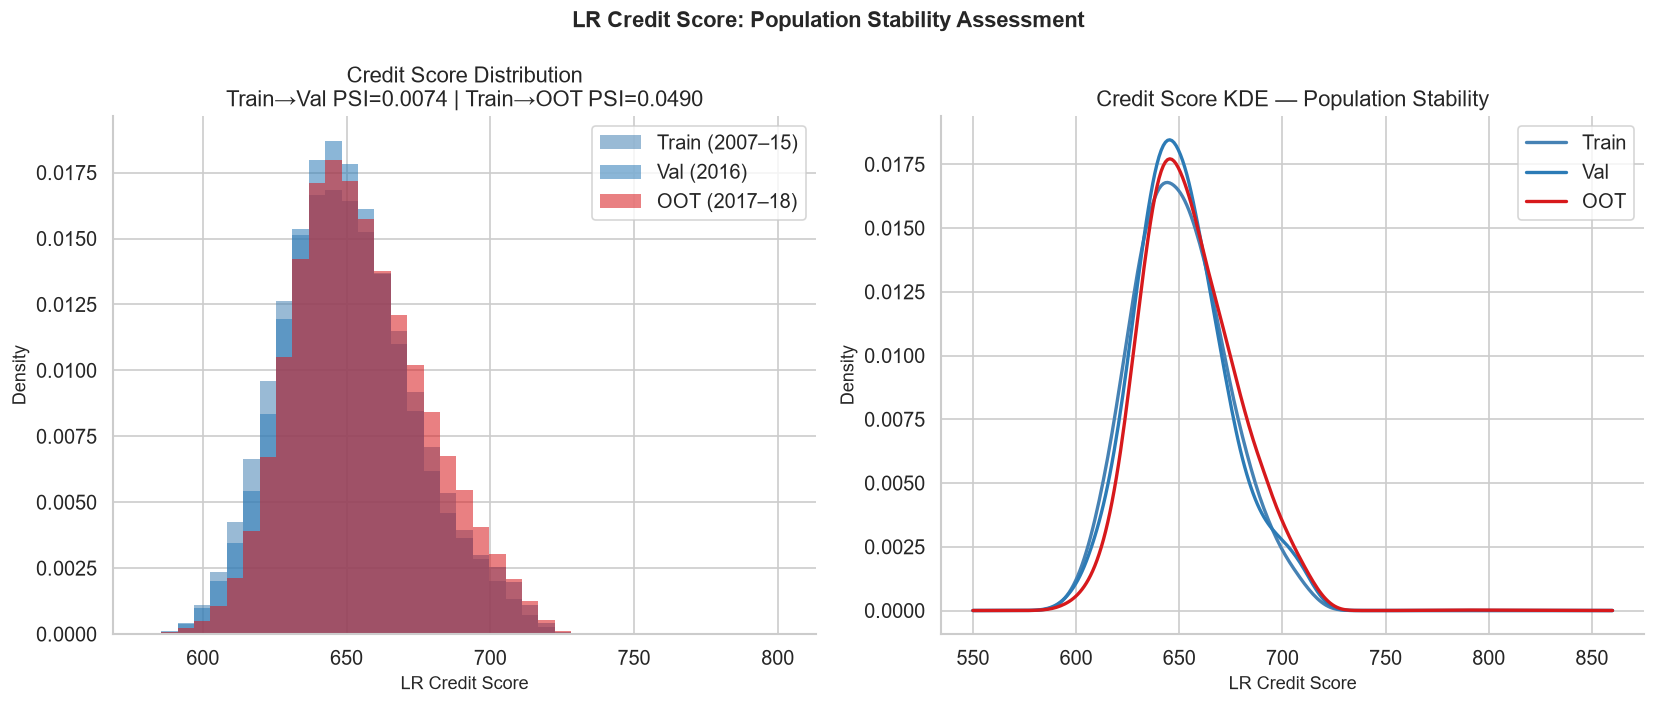

In [6]:
# ── Chart: Score distribution — Train vs Val vs OOT ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Histogram comparison
bins = np.linspace(sc_train.min(), sc_train.max(), 40)
for data, lbl, color in [(sc_train,'Train (2007–15)', 'steelblue'),
                          (sc_val,  'Val (2016)',      PLOT_COLOR),
                          (sc_oot,  'OOT (2017–18)',   ACCENT_COLOR)]:
    axes[0].hist(data, bins=bins, alpha=0.55, label=lbl, color=color,
                 density=True, edgecolor='none')
axes[0].set_xlabel('LR Credit Score')
axes[0].set_ylabel('Density')
axes[0].set_title(f'Credit Score Distribution\nTrain→Val PSI={psi_tv_score:.4f} | Train→OOT PSI={psi_to_score:.4f}')
axes[0].legend()

# KDE comparison
for data, lbl, color in [(sc_train,'Train','steelblue'),
                          (sc_val,  'Val',  PLOT_COLOR),
                          (sc_oot,  'OOT',  ACCENT_COLOR)]:
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(data, bw_method=0.15)
    x   = np.linspace(550, 860, 300)
    axes[1].plot(x, kde(x), label=lbl, color=color, linewidth=2)
axes[1].set_xlabel('LR Credit Score')
axes[1].set_ylabel('Density')
axes[1].set_title('Credit Score KDE — Population Stability')
axes[1].legend()

plt.suptitle('LR Credit Score: Population Stability Assessment', fontsize=13, fontweight='bold')
plt.tight_layout()
save_figure(fig, '09_psi_score_distribution.png')
plt.show()

---
## PSI Over Time — Year-by-Year Trend

PSI is computed for each calendar year against the training baseline.
This reveals when population shift began and whether drift is accelerating.

| Year | N Loans | PSI vs Train | Status |
|------|---------|------------|--------|
| 2007 | 574 | 0.1888 | 🟡 Monitor |
| 2008 | 2,393 | 0.2351 | 🟡 Monitor |
| 2009 | 5,281 | 0.6762 | 🔴 Unstable |
| 2010 | 12,537 | 0.2339 | 🟡 Monitor |
| 2011 | 21,721 | 0.2269 | 🟡 Monitor |
| 2012 | 53,367 | 0.0886 | 🟢 Stable |
| 2013 | 134,814 | 0.0102 | 🟢 Stable |
| 2014 | 235,629 | 0.0069 | 🟢 Stable |
| 2015 | 421,095 | 0.0039 | 🟢 Stable |
| 2016 | 434,406 | 0.0074 | 🟢 Stable |
| 2017 | 443,579 | 0.0246 | 🟢 Stable |
| 2018 | 495,242 | 0.0872 | 🟢 Stable |

**Key observations:**

1. **2009 spike (PSI = 0.676):** The 2008–2009 financial crisis created an anomalous
   borrower population. Lending Club was still a very small platform (5,281 loans in 2009),
   and the population was fundamentally different from later years — very high PSI due to
   tiny volume + crisis distortion. This is expected and not a model concern.

2. **2012–2018 stable corridor:** From 2012 onwards, the PSI is consistently below 0.10,
   confirming that the bulk of the training data (dominated by 2013–2015 loans) represents
   the model's target population well.

3. **2018 rising trend (0.087):** PSI is increasing toward the monitoring threshold
   in 2018, driven by the `int_rate` and utilisation shifts. This is the early signal
   that a model refresh may become necessary by 2019 if the trend continues.

In [7]:
# ── PSI over time (year-by-year vs training baseline) ────────────────────
train_with_year = train.copy()
train_with_year['year'] = pd.to_datetime(train['issue_d']).dt.year

# Include all years in the full dataset
all_data = pd.concat([train, val, oot], ignore_index=True)
all_data['year'] = pd.to_datetime(all_data['issue_d']).dt.year

# Compute LR score for all data
all_scores, _ = lr_score(all_data)
all_data['lr_score'] = all_scores

rows = []
for yr in sorted(all_data['year'].unique()):
    sub = all_data[all_data['year'] == yr]
    yr_psi = compute_psi(sc_train, sub['lr_score'].values)
    rows.append({'Year': int(yr), 'N_Loans': len(sub),
                 'PSI_vs_Train': round(yr_psi, 4),
                 'Status': psi_label(yr_psi)})

psi_over_time_df = pd.DataFrame(rows)
psi_over_time_df.to_csv('artifacts/psi_over_time.csv', index=False)
print(psi_over_time_df.to_string(index=False))

 Year  N_Loans  PSI_vs_Train   Status
 2007      574        0.1888  Monitor
 2008     2393        0.2351  Monitor
 2009     5281        0.6762 Unstable
 2010    12537        0.2339  Monitor
 2011    21721        0.2269  Monitor
 2012    53367        0.0886   Stable
 2013   134814        0.0102   Stable
 2014   235629        0.0069   Stable
 2015   421095        0.0039   Stable
 2016   434406        0.0074   Stable
 2017   443579        0.0246   Stable
 2018   495242        0.0872   Stable


---
## Feature Stability — Characteristic Stability Index (CSI)

CSI (Characteristic Stability Index) is PSI applied to individual input features rather than model scores — it identifies *which* features are driving any score distribution shift.

PSI computed for each of the 47 master features, comparing the training
distribution (2007–2015) to the OOT distribution (2017–2018).

### Summary

| Status | Count | Features |
|--------|-------|----------|
| 🟢 Stable (PSI < 0.10) | **43** | Most features stable |
| 🟡 Monitor (0.10–0.25) | **3** | `bc_util`, `revol_util`, `int_rate` |
| 🔴 Unstable (PSI > 0.25) | **1** | `initial_list_status` |

### Key Findings

**`initial_list_status` (PSI = 0.533 — Unstable):**  
This variable records whether a loan was listed as 'whole' (W) or 'fractional' (F) on the
Lending Club platform. The very high PSI reflects a **business operational change** by
Lending Club — not a change in borrower creditworthiness. This feature has very low
predictive power (IV = 0.0003) and was appropriately excluded from the LR scorecard.
It should be removed from the master feature set in any future model refresh.

**`bc_util` (PSI = 0.172), `revol_util` (PSI = 0.151) — Monitor:**  
Bank card and revolving utilisation rates have shifted moderately. Credit card usage
behaviour changed in the 2017–2018 period, likely reflecting macroeconomic and consumer
credit trends. These features remain predictive and are in the normal monitoring zone.

**`int_rate` (PSI = 0.124) — Monitor:**  
The interest rate distribution has shifted, consistent with Lending Club's evolving
pricing strategy and market conditions. The model's most important feature is in the
monitor zone — this warrants attention in any production deployment.

In [8]:
# ── Feature-level CSI — all 47 master features, Train vs OOT ─────────────
feat_psi_df = pd.read_csv('artifacts/psi_features.csv')
ALL_FEATURES = feat_psi_df['Feature'].tolist()
CAT_FEATURES = feat_psi_df[feat_psi_df['Type']=='categorical']['Feature'].tolist()

def feature_psi(base_series, actual_series, feat_type, n_bins=10):
    if feat_type == 'categorical':
        all_cats = set(base_series.dropna().unique()) | set(actual_series.dropna().unique())
        b = base_series.fillna('__missing__').value_counts(normalize=True)
        a = actual_series.fillna('__missing__').value_counts(normalize=True)
        all_cats = b.index.union(a.index)
        b = b.reindex(all_cats, fill_value=1e-6)
        a = a.reindex(all_cats, fill_value=1e-6)
        b /= b.sum(); a /= a.sum()
        return float(np.sum((a.values - b.values) * np.log(a.values / b.values)))
    else:
        base_clean   = base_series.dropna().values
        actual_clean = actual_series.dropna().values
        if len(base_clean) < 10 or len(actual_clean) < 10:
            return 0.0
        return compute_psi(base_clean, actual_clean, n_bins)

print('Computing CSI for 47 features (Train → OOT)...')
feat_rows = []
for feat in ALL_FEATURES:
    ftype = 'categorical' if feat in CAT_FEATURES else 'numerical'
    try:
        psi_val = feature_psi(train[feat], oot[feat], ftype)
    except Exception:
        psi_val = 0.0
    feat_rows.append({'Feature': feat, 'Type': ftype,
                      'PSI': round(psi_val, 4), 'Status': psi_label(psi_val)})

feat_psi_new = pd.DataFrame(feat_rows).sort_values('PSI', ascending=False).reset_index(drop=True)
feat_psi_new.to_csv('artifacts/psi_features.csv', index=False)
print(f'Saved psi_features.csv — {len(feat_psi_new)} features')
print()
print('Top 10 features by PSI:')
print(feat_psi_new.head(10)[['Feature','Type','PSI','Status']].to_string(index=False))

Computing CSI for 47 features (Train → OOT)...


Saved psi_features.csv — 47 features

Top 10 features by PSI:
            Feature        Type    PSI   Status
initial_list_status categorical 0.5332 Unstable
            bc_util   numerical 0.1718  Monitor
         revol_util   numerical 0.1507  Monitor
           int_rate   numerical 0.1246  Monitor
          sub_grade categorical 0.0885   Stable
     fico_range_low   numerical 0.0666   Stable
    fico_range_high   numerical 0.0666   Stable
              grade categorical 0.0638   Stable
verification_status categorical 0.0623   Stable
     inq_last_6mths   numerical 0.0532   Stable


2026-08-01 02:15:56 | INFO     | src.utils | Figure saved → reports\09_psi_features.png


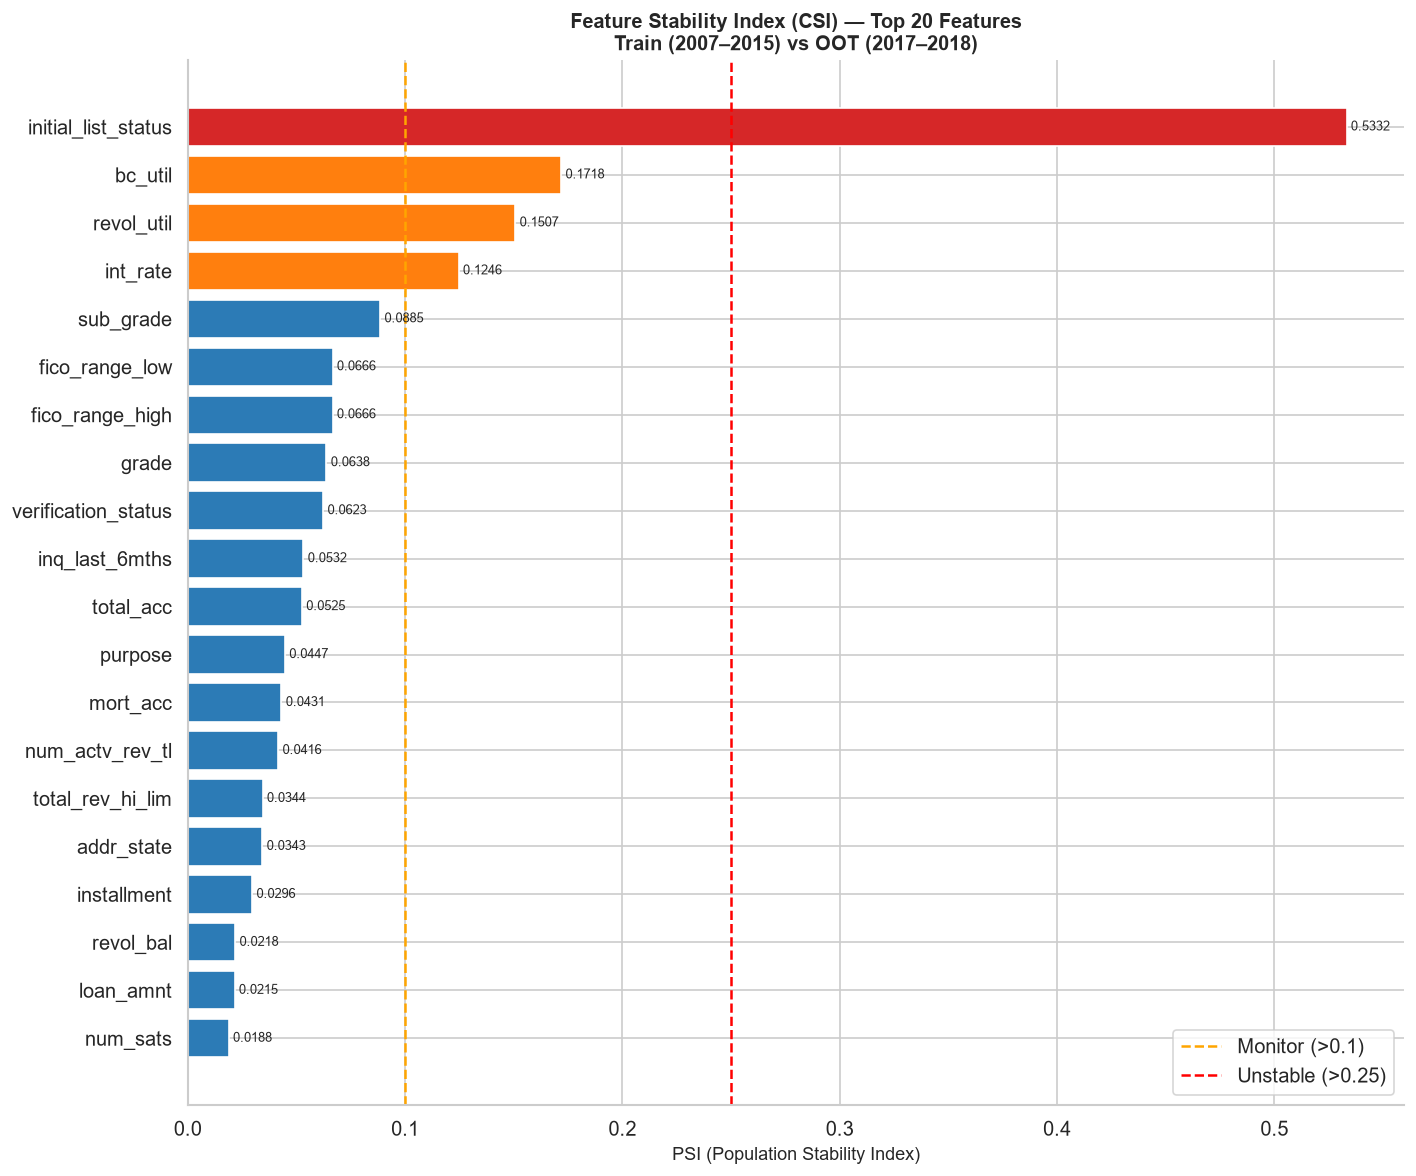

In [9]:
# ── Chart: Feature PSI bar chart ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 10))

top_n = feat_psi_new.head(20)
colors = []
for v in top_n['PSI']:
    if v >= PSI_MONITOR: colors.append('#d62728')
    elif v >= PSI_STABLE: colors.append('#ff7f0e')
    else: colors.append(PLOT_COLOR)

bars = ax.barh(top_n['Feature'][::-1], top_n['PSI'][::-1], color=colors[::-1])
ax.axvline(PSI_STABLE,  color='orange', linestyle='--', linewidth=1.5, label=f'Monitor (>{PSI_STABLE})')
ax.axvline(PSI_MONITOR, color='red',    linestyle='--', linewidth=1.5, label=f'Unstable (>{PSI_MONITOR})')
ax.set_xlabel('PSI (Population Stability Index)', fontsize=11)
ax.set_title('Feature Stability Index (CSI) — Top 20 Features\nTrain (2007–2015) vs OOT (2017–2018)',
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right')

for bar, v in zip(bars, top_n['PSI'][::-1]):
    ax.text(bar.get_width()+0.002, bar.get_y()+bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=8)

plt.tight_layout()
save_figure(fig, '09_psi_features.png')
plt.show()

In [10]:
# ── psi_feature_wise.csv — RF top-15 numerical features, Train→Val + Train→OOT ──
rf_importance = pd.read_csv('artifacts/rf_feature_importance.csv')

# Top-15 RF features, numerical only (exclude sub_grade rank-1, grade rank-2)
top15_num = rf_importance.head(15)[~rf_importance.head(15)['Feature'].isin(CAT_FEATURES)]

fw_rows = []
for _, row in top15_num.iterrows():
    feat  = row['Feature']
    rf_rk = int(row['RF_Rank'])
    try:
        psi_tv_f = feature_psi(train[feat], val[feat], 'numerical')
        psi_to_f = feature_psi(train[feat], oot[feat], 'numerical')
    except Exception:
        psi_tv_f = psi_to_f = 0.0
    fw_rows.append({
        'Feature':      feat,
        'RF Rank':      rf_rk,
        'PSI (T→Val)':  round(psi_tv_f, 4),
        'Val Status':   psi_label(psi_tv_f),
        'PSI (T→OOT)':  round(psi_to_f, 4),
        'OOT Status':   psi_label(psi_to_f),
    })

feat_wise_df = pd.DataFrame(fw_rows)
feat_wise_df.to_csv('artifacts/psi_feature_wise.csv', index=False)
print(f'Saved psi_feature_wise.csv — {len(feat_wise_df)} features (RF top-15 numerical)')
print()
print(feat_wise_df.to_string(index=False))

Saved psi_feature_wise.csv — 13 features (RF top-15 numerical)

             Feature  RF Rank  PSI (T→Val) Val Status  PSI (T→OOT) OOT Status
            int_rate        3       0.0899     Stable       0.1246    Monitor
                term        4       0.0000     Stable       0.0000     Stable
acc_open_past_24mths        5       0.0105     Stable       0.0033     Stable
                 dti        6       0.0060     Stable       0.0141     Stable
      fico_range_low        7       0.0011     Stable       0.0666     Stable
     fico_range_high        8       0.0011     Stable       0.0666     Stable
          annual_inc        9       0.0081     Stable       0.0136     Stable
     tot_hi_cred_lim       10       0.0038     Stable       0.0104     Stable
         tot_cur_bal       11       0.0014     Stable       0.0109     Stable
         installment       12       0.0150     Stable       0.0296     Stable
           loan_amnt       13       0.0069     Stable       0.0215     Stable


---
## Feature Distribution Shift — Highest-PSI Features

Distribution comparison (train vs OOT) for the four features with PSI > 0.10.


**`initial_list_status`:** The proportion of W vs F listings has shifted dramatically —
a business rule change, not borrower drift. Confirm and exclude from future models.

**`bc_util` and `revol_util`:** The distributions have shifted toward higher values in
2017–2018, indicating that borrowers are using more of their available credit. This is
a genuine macroeconomic signal and could affect model performance.

**`int_rate`:** The OOT distribution shows a shift toward higher interest rates,
consistent with Lending Club's risk-adjusted pricing evolution and the rising rate
environment of 2017–2018.

2026-08-01 02:16:08 | INFO     | src.utils | Figure saved → reports\09_psi_feature_distributions.png


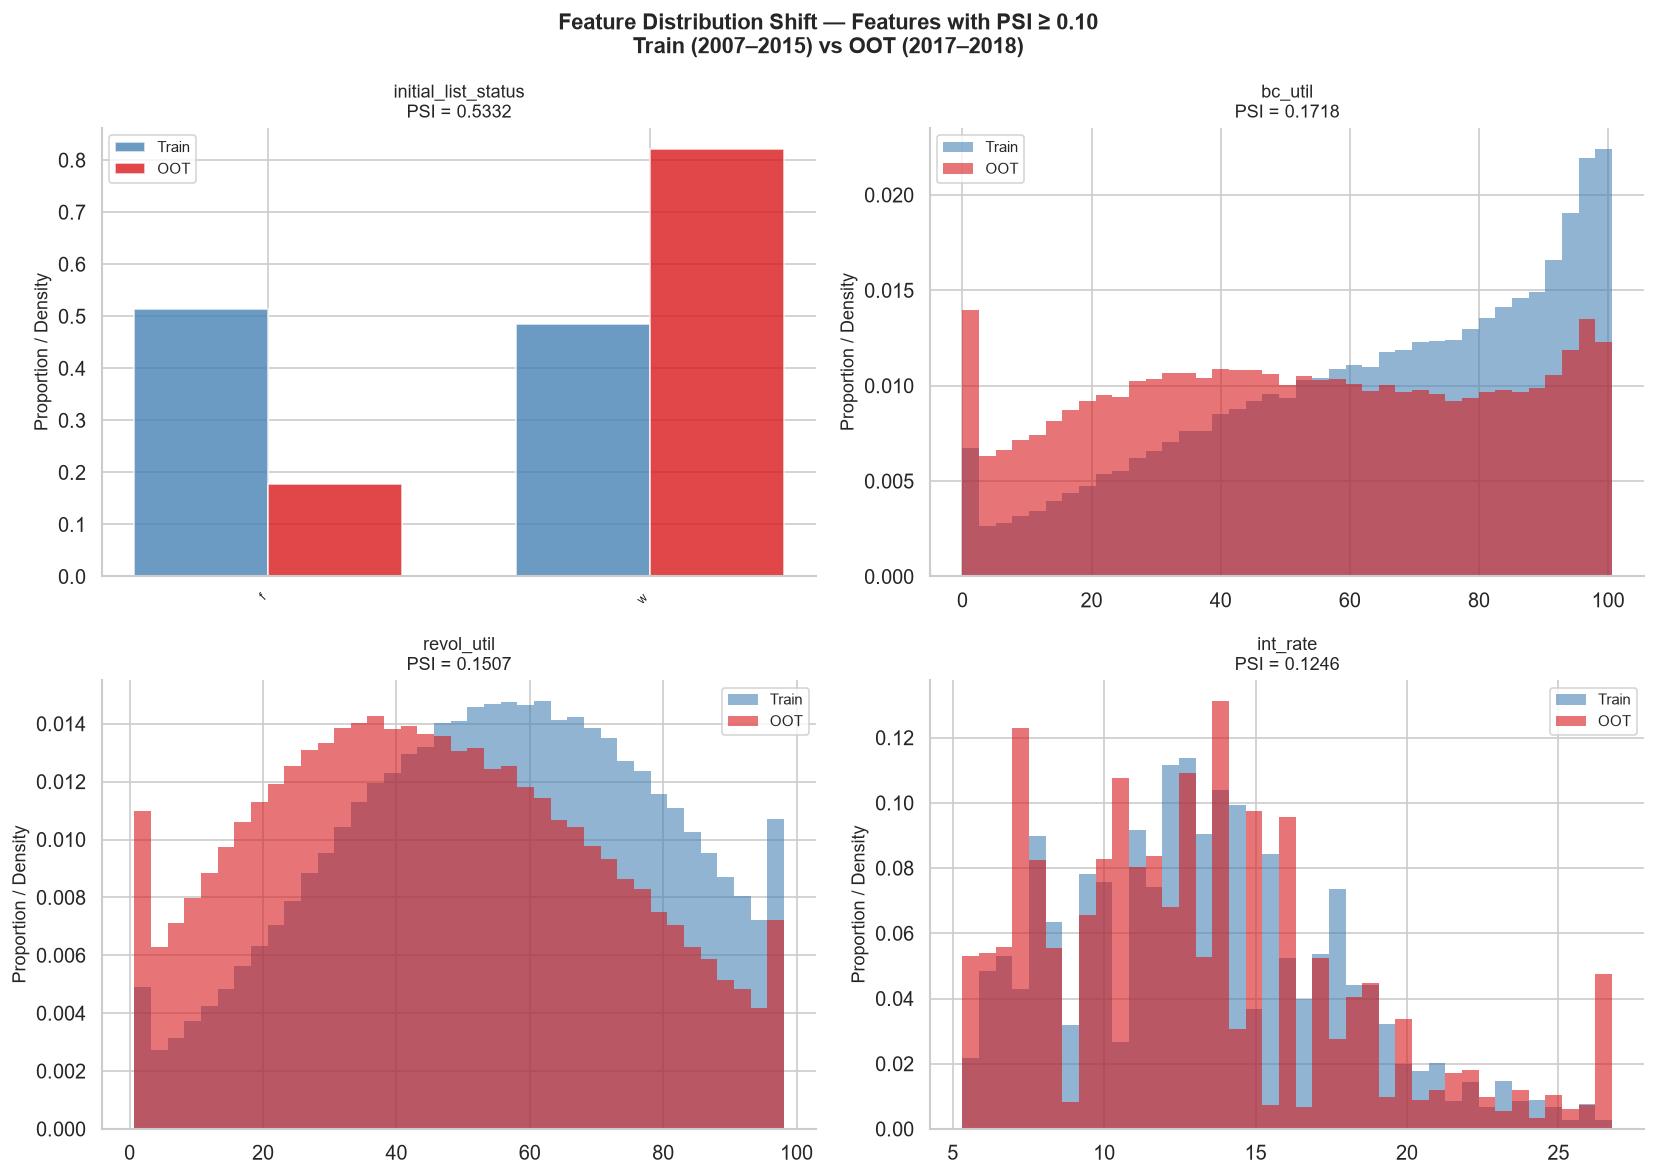

In [11]:
# ── Feature distribution shift — top-PSI features ────────────────────────
top_feats = feat_psi_new[feat_psi_new['PSI'] >= PSI_STABLE].head(4)['Feature'].tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Feature Distribution Shift — Features with PSI ≥ 0.10\n'
             'Train (2007–2015) vs OOT (2017–2018)',
             fontsize=13, fontweight='bold')

for ax, feat in zip(axes.flat, top_feats):
    ftype = 'categorical' if feat in CAT_FEATURES else 'numerical'
    psi_v = feat_psi_new[feat_psi_new['Feature']==feat]['PSI'].values[0]

    if ftype == 'categorical':
        all_cats = sorted(set(train[feat].dropna().astype(str).unique()) |
                          set(oot[feat].dropna().astype(str).unique()))
        b = train[feat].astype(str).value_counts(normalize=True).reindex(all_cats, fill_value=0)
        a = oot[feat].astype(str).value_counts(normalize=True).reindex(all_cats, fill_value=0)
        x   = np.arange(len(all_cats))
        w   = 0.35
        ax.bar(x - w/2, b.values, w, color='steelblue', alpha=0.8, label='Train')
        ax.bar(x + w/2, a.values, w, color=ACCENT_COLOR, alpha=0.8, label='OOT')
        ax.set_xticks(x)
        ax.set_xticklabels(all_cats, rotation=45, ha='right', fontsize=7)
    else:
        t_clean = train[feat].dropna().values
        o_clean = oot[feat].dropna().values
        lo = np.percentile(np.concatenate([t_clean, o_clean]), 1)
        hi = np.percentile(np.concatenate([t_clean, o_clean]), 99)
        bins = np.linspace(lo, hi, 40)
        ax.hist(t_clean.clip(lo, hi), bins=bins, density=True,
                alpha=0.6, color='steelblue', label='Train', edgecolor='none')
        ax.hist(o_clean.clip(lo, hi), bins=bins, density=True,
                alpha=0.6, color=ACCENT_COLOR, label='OOT', edgecolor='none')

    ax.set_title(f'{feat}\nPSI = {psi_v:.4f}', fontsize=11)
    ax.set_ylabel('Proportion / Density')
    ax.legend(fontsize=9)

plt.tight_layout()
save_figure(fig, '09_psi_feature_distributions.png')
plt.show()

In [12]:
print('=== PSI Monitoring — Summary ===')
print()
print('Model score stability (Train → OOT):')
for _, row in psi_overall_df.iterrows():
    print(f'  {row["Model"]:22s} PSI={row["PSI (Train→OOT)"]:.4f}  {row["PSI OOT Status"]}')
print()
print(f'Feature stability (47 features, Train → OOT):')
for status in ['Stable','Monitor','Unstable']:
    sub = feat_psi_new[feat_psi_new['Status']==status]
    print(f'  {status:10s}: {len(sub):2d} features')
print()
print('Saved artifacts:')
for a in ['artifacts/psi_scores.csv','artifacts/psi_overall.csv',
          'artifacts/psi_features.csv','artifacts/psi_over_time.csv',
          'artifacts/psi_feature_wise.csv']:
    print(f'  {a}')
print()
print('Saved reports:')
for r in ['reports/09_psi_score_distribution.png',
          'reports/09_psi_features.png',
          'reports/09_psi_feature_distributions.png']:
    print(f'  {r}')

=== PSI Monitoring — Summary ===

Model score stability (Train → OOT):
  Logistic Regression    PSI=0.0490  Stable
  Random Forest          PSI=0.0430  Stable
  XGBoost                PSI=0.0412  Stable
  Cox PHM                PSI=0.0324  Stable

Feature stability (47 features, Train → OOT):
  Stable    : 43 features
  Monitor   :  3 features
  Unstable  :  1 features

Saved artifacts:
  artifacts/psi_scores.csv
  artifacts/psi_overall.csv
  artifacts/psi_features.csv
  artifacts/psi_over_time.csv
  artifacts/psi_feature_wise.csv

Saved reports:
  reports/09_psi_score_distribution.png
  reports/09_psi_features.png
  reports/09_psi_feature_distributions.png


---
## Monitoring Conclusions & Recommendations

### Overall Assessment

| Component | PSI (Train→OOT) | Status | Recommendation |
|-----------|----------------|--------|----------------|
| LR Credit Score | 0.049 | 🟢 **Stable** | No action required |
| PD Distribution | 0.049 | 🟢 **Stable** | No action required |
| `int_rate` | 0.124 | 🟡 Monitor | Watch closely; key scorecard feature |
| `bc_util` | 0.172 | 🟡 Monitor | Monitor credit utilisation trend |
| `revol_util` | 0.151 | 🟡 Monitor | Monitor revolving utilisation trend |
| `initial_list_status` | 0.533 | 🔴 Unstable | Exclude from future models (operational change, low IV) |

### Summary

The LR credit scorecard is **population-stable** through the OOT period (2017–2018).
The model output distribution (credit score and PD) has not shifted significantly
from the training period — both remain within the stable zone (PSI < 0.10).

43 out of 47 features are stable. The three monitoring-zone features (`int_rate`,
`bc_util`, `revol_util`) reflect genuine macroeconomic trends and should be tracked
over time. The single unstable feature (`initial_list_status`) is a business operational
artefact with negligible predictive power and should be excluded from future model versions.

### Production Trigger Thresholds

In a production deployment, the following monitoring triggers would be recommended:

| Trigger | Threshold | Action |
|---------|-----------|--------|
| Model score PSI | > 0.10 | Investigate + consider recalibration |
| Model score PSI | > 0.25 | Full model redevelopment |
| `int_rate` PSI | > 0.25 | Review model inputs and re-estimate |
| Key feature PSI > 0.25 | Any feature | Flag for model owner review |
| Overall default rate shift | > ±3 pp from training | Recalibrate PD model |

### Saved Artifacts

| Artifact | Description |
|----------|-------------|
| `artifacts/psi_scores.csv` | Model score PSI (train→val, train→oot) |
| `artifacts/psi_features.csv` | Feature-wise PSI for all 47 features |
| `artifacts/psi_over_time.csv` | Year-by-year PSI trend |

### Saved Reports

`09_psi_features.png` · `09_psi_score_distribution.png` · `09_psi_feature_distributions.png`